# Binomial Distribution

Companion notebook for the [binomial distribution note](../../notes/random_variables_and_distributions/discrete/binomial_distribution.md) and its [exercises](../../exercises/random_variables_and_distributions/binomial_distribution.md).

$X\sim\text{Binomial}(n,p)$ counts the successes in $n$ independent Bernoulli($p$) trials:

$$P(X=k)=\binom nk p^k(1-p)^{n-k},\qquad E[X]=np,\qquad \operatorname{Var}(X)=np(1-p).$$

We implement the PMF and CDF by hand, check them against `scipy.stats.binom`, plot them, and then compare with simulated data.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)  # seeded for reproducible simulations

## Hand-rolled implementation

The PMF follows the formula directly with `math.comb`. The CDF is the cumulative sum of the PMF over the support $0,\dots,n$.

In [2]:
class BinomialDistribution:
    def __init__(self, n, p):
        self.n = n
        self.p = p

    def pmf(self, k):
        k = np.asarray(k)
        return np.array([math.comb(self.n, int(i)) * self.p**i * (1 - self.p) ** (self.n - i)
                         for i in k.ravel()]).reshape(k.shape)

    def cdf(self, k):
        k = np.asarray(k)
        cum = np.cumsum(self.pmf(np.arange(self.n + 1)))
        return cum[np.clip(k, 0, self.n).astype(int)]

    def mean(self):
        return self.n * self.p

    def var(self):
        return self.n * self.p * (1 - self.p)

## Check against `scipy.stats`

Two parameter sets are used throughout. `np.allclose` confirms that the hand-rolled formulas agree with the library to floating-point precision.

In [3]:
n1, p1 = 10, 0.5
n2, p2 = 15, 0.7
k1, k2 = np.arange(n1 + 1), np.arange(n2 + 1)

d1, d2 = BinomialDistribution(n1, p1), BinomialDistribution(n2, p2)
pmf1, pmf2 = stats.binom.pmf(k1, n1, p1), stats.binom.pmf(k2, n2, p2)
cdf1, cdf2 = stats.binom.cdf(k1, n1, p1), stats.binom.cdf(k2, n2, p2)

print("PMF matches:", np.allclose(d1.pmf(k1), pmf1), np.allclose(d2.pmf(k2), pmf2))
print("CDF matches:", np.allclose(d1.cdf(k1), cdf1), np.allclose(d2.cdf(k2), cdf2))
print("PMF sums to", d1.pmf(k1).sum())

PMF matches: True True
CDF matches: True True
PMF sums to 1.0


## Shape of the PMF and CDF

With $p=0.5$ the PMF is symmetric around $np=5$; with $p=0.7$ it is left-skewed with mean $10.5$. The CDF is a right-continuous step function that jumps by $P(X=k)$ at each integer.

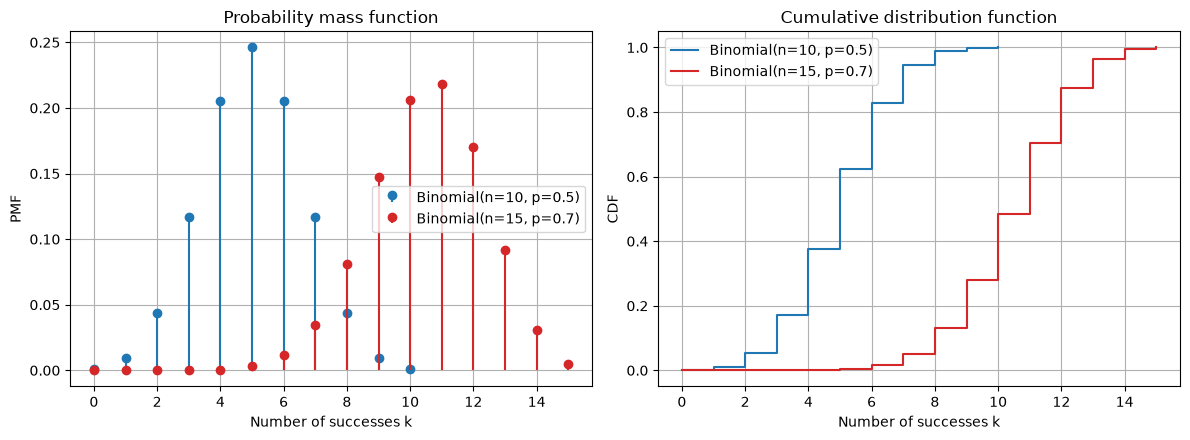

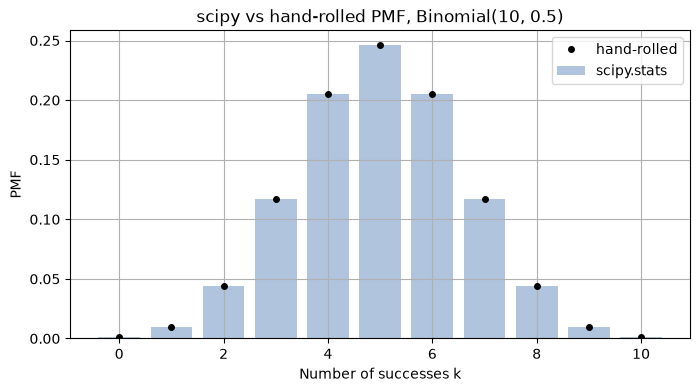

In [4]:
def plot_pmf_cdf(x1, pmf1, cdf1, label1, x2, pmf2, cdf2, label2, xlabel):
    """PMF (stem) and CDF (step) of two distributions side by side."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    ax1.stem(x1, pmf1, basefmt=" ", linefmt="C0-", markerfmt="C0o", label=label1)
    ax1.stem(x2, pmf2, basefmt=" ", linefmt="C3-", markerfmt="C3o", label=label2)
    ax1.set(xlabel=xlabel, ylabel="PMF", title="Probability mass function")
    ax2.step(x1, cdf1, where="post", color="C0", label=label1)
    ax2.step(x2, cdf2, where="post", color="C3", label=label2)
    ax2.set(xlabel=xlabel, ylabel="CDF", title="Cumulative distribution function")
    for ax in (ax1, ax2):
        ax.legend()
        ax.grid(True)
    plt.tight_layout()
    plt.show()


def plot_overlay(x, ref, custom, xlabel, title):
    """Hand-rolled values (dots) on top of the scipy.stats values (bars)."""
    plt.figure(figsize=(8, 4))
    plt.bar(x, ref, color="lightsteelblue", label="scipy.stats")
    plt.plot(x, custom, "ko", markersize=4, label="hand-rolled")
    plt.xlabel(xlabel)
    plt.ylabel("PMF")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


plot_pmf_cdf(k1, pmf1, cdf1, f"Binomial(n={n1}, p={p1})",
             k2, pmf2, cdf2, f"Binomial(n={n2}, p={p2})", "Number of successes k")
plot_overlay(k1, pmf1, d1.pmf(k1), "Number of successes k", "scipy vs hand-rolled PMF, Binomial(10, 0.5)")

## Worked example: email security audit

From the note: 90% of employees follow the protocol and 10 are audited, so $X\sim\text{Binomial}(10,0.9)$. The `sf` (survival function) gives $P(X>k)$.

In [5]:
audit = BinomialDistribution(10, 0.9)
p_eq_7 = audit.pmf(7)
p_ge_8 = 1 - audit.cdf(7)
p_lt_5 = audit.cdf(4)
print(f"P(X = 7)  = {p_eq_7:.4f}   scipy: {stats.binom.pmf(7, 10, 0.9):.4f}")
print(f"P(X >= 8) = {p_ge_8:.4f}   scipy: {stats.binom.sf(7, 10, 0.9):.4f}")
print(f"P(X < 5)  = {p_lt_5:.6f}   scipy: {stats.binom.cdf(4, 10, 0.9):.6f}")

P(X = 7)  = 0.0574   scipy: 0.0574
P(X >= 8) = 0.9298   scipy: 0.9298
P(X < 5)  = 0.000147   scipy: 0.000147


## Simulation versus theory

We draw 100,000 values with a seeded generator. Sample moments should be close to $np$ and $np(1-p)$, and the relative frequencies close to the PMF.

mean: sample 10.498  theory 10.500
var : sample 3.153  theory 3.150


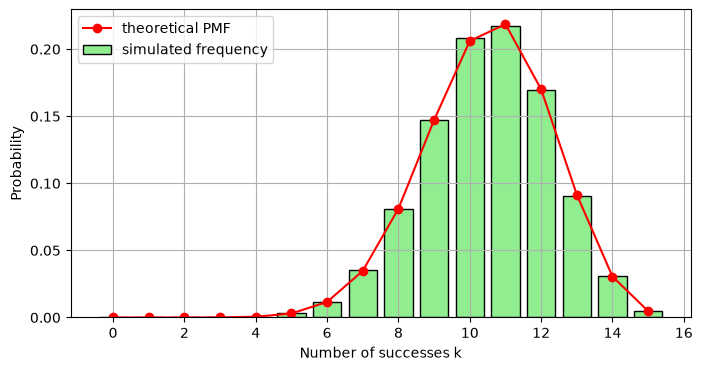

In [6]:
sample = rng.binomial(n2, p2, size=100_000)
print(f"mean: sample {sample.mean():.3f}  theory {d2.mean():.3f}")
print(f"var : sample {sample.var():.3f}  theory {d2.var():.3f}")

freq = np.bincount(sample, minlength=n2 + 1) / sample.size
plt.figure(figsize=(8, 4))
plt.bar(k2, freq, color="lightgreen", edgecolor="black", label="simulated frequency")
plt.plot(k2, d2.pmf(k2), "ro-", label="theoretical PMF")
plt.xlabel("Number of successes k")
plt.ylabel("Probability")
plt.legend()
plt.grid(True)
plt.show()

## Takeaways

* Hand-rolled PMF/CDF agree with `scipy.stats.binom`.
* The mean $np$ and variance $np(1-p)$ are confirmed by simulation.
* For large $n$ and small $p$ the binomial is close to Poisson($np$); see the [Poisson notebook](poisson_distribution.ipynb).